# Spotify Artist Popularity Ranking — Standalone Analysis

**Research question:** How can cumulative streaming success and current daily listening activity be combined into an interpretable artist popularity ranking?

**Input:** `artists.csv` 

**Important limitations:** The dataset is a ranked/top-artist sample, not all Spotify artists. These are *snapshot-relative* rankings, not proof of song-level predictive ability. Figures are in **millions of streams**. Daily means **millions of streams per day** at capture. The weights below are a starting hypothesis, not a validated scientific scale.

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path = Path("artists.csv")
if not path.exists():
    raise FileNotFoundError("Put artists.csv in the same directory as this notebook")
raw = pd.read_csv(path)
print("Shape:", raw.shape)
display(raw.head())

Shape: (3000, 6)


,Artist,Streams,Daily,As lead,Solo,As feature
0,Drake,"85,041.3",50.775,"57,252.6","32,681.6","27,788.7"
1,Bad Bunny,"67,533.0",44.820,"40,969.6","23,073.0","26,563.4"
2,Taylor Swift,"57,859.0",85.793,"55,566.7","50,425.7","2,292.4"
3,The Weeknd,"53,665.2",44.437,"42,673.3","31,164.2","10,991.9"
4,Ed Sheeran,"47,907.7",17.506,"42,767.9","33,917.0","5,139.8"


## 1. Clean and audit the artist data

`Streams`, `As lead`, `Solo`, and `As feature` often contain commas. **Do not sum** the role-based columns into total streams; `Solo` is a subset of lead and lead/feature represent overlapping categories of credit. We keep duplicated names visible rather than merging potentially different artists (e.g., two entries named “Eve”).

In [12]:
df = raw.copy()
num_cols = ["Streams", "Daily", "As lead", "Solo", "As feature"]
for col in num_cols:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

print("Missing values:\n", df.isna().sum().to_string())
print("\nDuplicated artist names:\n", df.loc[df["Artist"].duplicated(keep=False), ["Artist", "Streams", "Daily"]].to_string(index=False))
print("\nSummary (millions):")
display(df[num_cols].describe())

Missing values:
 Artist          0
Streams         0
Daily           6
As lead        16
Solo           69
As feature    338

Duplicated artist names:
 Artist  Streams  Daily
   Eve   1339.8  0.882
   Eve   1095.1  0.994

Summary (millions):


,Streams,Daily,As lead,Solo,As feature
count,3000.0,2994.0,2984.0,2931.0,2662.0
mean,2914.439967,1.854522,2152.79055,1519.900409,871.298685
std,4826.306507,3.758283,3590.730797,2736.927669,1965.651524
min,728.6,0.002,0.5,0.1,0.1
25%,961.2,0.48025,751.375,360.3,70.025
50%,1459.4,0.871,1109.15,803.7,295.6
75%,2680.8,1.77425,2079.9,1543.75,838.925
max,85041.3,85.793,57252.6,50425.7,27788.7


## 2. Explore career size versus present activity

A high cumulative stream count need not imply a high current daily count. Because both variables are strongly skewed, plot them on logarithmic axes.

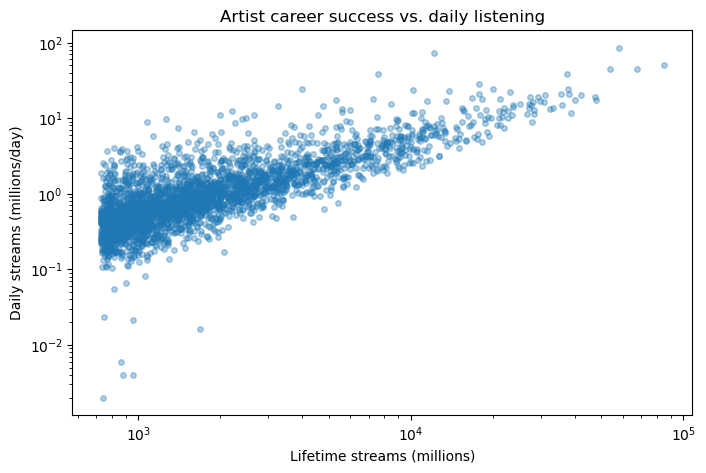

Spearman correlation: 0.753


In [13]:
plot_df = df.loc[(df["Streams"] > 0) & (df["Daily"] > 0)].copy()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(plot_df["Streams"], plot_df["Daily"], alpha=0.35, s=16)
ax.set(xscale="log", yscale="log", xlabel="Lifetime streams (millions)", ylabel="Daily streams (millions/day)", title="Artist career success vs. daily listening")
plt.show()
print("Spearman correlation:", round(plot_df[["Streams", "Daily"]].corr(method="spearman").iloc[0, 1], 3))

## 3. Build the Artist Popularity Score (APS)

1. Apply `log1p` to reduce the disproportionate influence of superstar counts.
2. Convert each transformed variable to a percentile from 0 to 100 *within the observed sample*.
3. Average lifetime and daily percentiles with equal weights.

Transfromed usings **log1(p(x)) = ln(1+x)** so top heavy artists don't drastically outweigh the bottom. May not be that big of an issue with the top charts of 2023. The 1 is added incase we have x = 0.

\[
APS_j = 0.5\, P_{{lifetime}} + 0.5\, P_{{daily}}
\]

This is a transparent **composite ranking**, not an externally calibrated Spotify popularity score. Artists without a valid `Daily` value are omitted from the main combined ranking; they remain in the cleaned data.

In [14]:
ranked = df.loc[(df["Streams"] >= 0) & (df["Daily"] >= 0)].copy()
ranked["log_lifetime"] = np.log1p(ranked["Streams"])
ranked["log_daily"] = np.log1p(ranked["Daily"])
ranked["career_percentile"] = ranked["log_lifetime"].rank(pct=True) * 100
ranked["daily_percentile"] = ranked["log_daily"].rank(pct=True) * 100

LIFETIME_WEIGHT = 0.50
ranked["APS"] = (LIFETIME_WEIGHT * ranked["career_percentile"]
                 + (1 - LIFETIME_WEIGHT) * ranked["daily_percentile"])
ranked = ranked.sort_values(["APS", "Streams"], ascending=False).copy()
ranked["APS_rank"] = ranked["APS"].rank(ascending=False, method="min").astype(int)
print(f"Ranked {len(ranked):,} artists; omitted {len(df)-len(ranked)} with unavailable daily/stream values")
display(ranked[["APS_rank", "Artist", "Streams", "Daily", "career_percentile", "daily_percentile", "APS"]].head(20).round(2))

Ranked 2,994 artists; omitted 6 with unavailable daily/stream values


,APS_rank,Artist,Streams,Daily,career_percentile,daily_percentile,APS
0,1,Drake,85041.3,50.78,100.00,99.93,99.97
2,1,Taylor Swift,57859.0,85.79,99.93,100.00,99.97
1,3,Bad Bunny,67533.0,44.82,99.97,99.90,99.93
3,4,The Weeknd,53665.2,44.44,99.90,99.87,99.88
11,5,Travis Scott,37489.0,38.36,99.63,99.83,99.73
10,6,Kanye West,37667.2,24.16,99.67,99.67,99.67
9,7,Post Malone,38002.7,21.1,99.70,99.53,99.62
6,8,Eminem,42029.0,20.18,99.80,99.40,99.60
5,9,Justin Bieber,47525.7,18.87,99.83,99.30,99.57
13,10,Rihanna,35501.8,20.78,99.57,99.47,99.52


## 4. Compare original lifetime ranking against composite popularity

Look for artists with large differences between current momentum and career accumulation. Differences are **descriptive**, not evidence of increasing or decreasing popularity over time (we have only one snapshot).

In [15]:
ranked["career_rank"] = ranked["Streams"].rank(ascending=False, method="min")
ranked["daily_rank"] = ranked["Daily"].rank(ascending=False, method="min")
ranked["rank_shift"] = ranked["career_rank"] - ranked["APS_rank"]
print("Artists ranked much higher by combined score than lifetime streams:")
display(ranked.nlargest(12, "rank_shift")[["Artist", "career_rank", "daily_rank", "APS_rank", "rank_shift"]])
print("Artists ranked lower by combined score than lifetime streams:")
display(ranked.nsmallest(12, "rank_shift")[["Artist", "career_rank", "daily_rank", "APS_rank", "rank_shift"]])

Artists ranked much higher by combined score than lifetime streams:


,Artist,career_rank,daily_rank,APS_rank,rank_shift
2854,Luan Pereira,2849.0,324.0,1569,1280.0
2937,Wankelmut,2932.0,505.0,1713,1219.0
2666,Lefty Sm,2664.0,288.0,1450,1214.0
2908,Nadin Amizah,2904.0,541.0,1716,1188.0
2737,Wall Hein,2735.0,444.0,1573,1162.0
2999,Ayra Starr,2993.0,705.0,1863,1130.0
2524,Milo j,2522.0,326.0,1394,1128.0
2469,Supernova Ent,2466.0,303.0,1339,1127.0
2518,Vulgo FK,2516.0,336.0,1396,1120.0
2785,INTERWORLD,2783.0,632.0,1697,1086.0


Artists ranked lower by combined score than lifetime streams:


,Artist,career_rank,daily_rank,APS_rank,rank_shift
1008,Bing Crosby,1009.0,2941.0,2001,-992.0
1276,Upchurch,1276.0,2990.0,2164,-888.0
1065,Kiiara,1066.0,2786.0,1950,-884.0
1159,Marc E. Bassy,1160.0,2809.0,2014,-854.0
1072,Lil Dicky,1073.0,2694.0,1902,-829.0
1193,Gavin James,1194.0,2783.0,2019,-825.0
1021,Digital Farm Animals,1022.0,2644.0,1843,-821.0
1180,Jack Ã,1181.0,2754.0,1995,-814.0
1099,MadeinTYO,1100.0,2671.0,1908,-808.0
769,Desiigner,770.0,2409.0,1575,-805.0


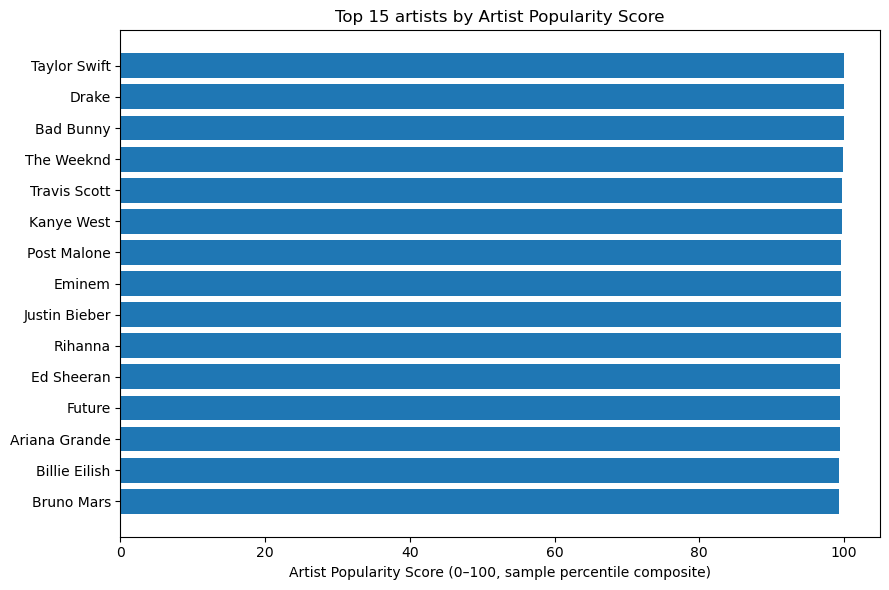

In [16]:
top = ranked.nsmallest(15, "APS_rank").sort_values("APS")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["Artist"], top["APS"])
ax.set(xlabel="Artist Popularity Score (0–100, sample percentile composite)", title="Top 15 artists by Artist Popularity Score")
plt.tight_layout()
plt.show()

## 5. Sensitivity test: do weights change the rankings?

Recompute scores when the importance of historical versus daily streams changes. Because weights are judgment calls, stability across plausible settings is important.

In [17]:
for lifetime_weight in [0.25, 0.50, 0.75]:
    col = f"APS_lifetime_{int(100*lifetime_weight)}"
    ranked[col] = (lifetime_weight * ranked["career_percentile"]
                   + (1-lifetime_weight) * ranked["daily_percentile"])
    print(f"\nTop 10 — lifetime weight {lifetime_weight:.0%}:")
    display(ranked.nlargest(10, col)[["Artist", col]].round(2))


Top 10 — lifetime weight 25%:


,Artist,APS_lifetime_25
2,Taylor Swift,99.98
0,Drake,99.95
1,Bad Bunny,99.92
3,The Weeknd,99.87
11,Travis Scott,99.78
10,Kanye West,99.67
9,Post Malone,99.57
6,Eminem,99.50
13,Rihanna,99.49
16,Future,99.44



Top 10 — lifetime weight 50%:


,Artist,APS_lifetime_50
0,Drake,99.97
2,Taylor Swift,99.97
1,Bad Bunny,99.93
3,The Weeknd,99.88
11,Travis Scott,99.73
10,Kanye West,99.67
9,Post Malone,99.62
6,Eminem,99.60
5,Justin Bieber,99.57
13,Rihanna,99.52



Top 10 — lifetime weight 75%:


,Artist,APS_lifetime_75
0,Drake,99.98
2,Taylor Swift,99.95
1,Bad Bunny,99.95
3,The Weeknd,99.89
6,Eminem,99.70
5,Justin Bieber,99.70
4,Ed Sheeran,99.68
11,Travis Scott,99.68
10,Kanye West,99.67
9,Post Malone,99.66


## 6. Explore solo and featured contributions (secondary descriptive analysis)

These are **not independent components** of total streams. They can illuminate artist roles, but should not be added together as if they were new streams.

A **feature_share mean** of .274 means that the average artist has 27.4% of their streams from features. 

Median feature_share is about **20%**, meaning half of the artists have 20% of their streams from features.

In [18]:
roles = df.loc[df["Streams"].gt(0)].copy()
roles["feature_share"] = roles["As feature"] / roles["Streams"]
roles["solo_share"] = roles["Solo"] / roles["Streams"]
print("Role ratios (nonmissing rows):")
display(roles[["feature_share", "solo_share"]].describe().round(3))

Role ratios (nonmissing rows):


,feature_share,solo_share
count,2662.0,2931.0
mean,0.274,0.551
std,0.268,0.342
min,0.0,0.0
25%,0.048,0.24
50%,0.197,0.566
75%,0.424,0.898
max,1.0,1.0


## 7. Export results and document limitations

- `artist_popularity_rankings.csv`: all artists with both streaming statistics, sorted by APS.
- The top-3,000 sample is selective. Percentiles reflect **only this set of artists**.
- Name collisions mean `Artist` is not a globally unique ID.
- To later predict song popularity, acquire dated *pre-release* artist metrics and link with artist IDs; this single snapshot is not enough for leakage-free historical prediction.

How to connect this score into predicting populartiy? 

In [19]:
columns = ["APS_rank", "Artist", "APS", "Streams", "Daily", "career_percentile", "daily_percentile", "career_rank", "daily_rank", "rank_shift"]
ranked[columns].sort_values("APS_rank").to_csv("artist_popularity_rankings.csv", index=False)
print("Saved artist_popularity_rankings.csv")

Saved artist_popularity_rankings.csv
